## Hotel Booking Cancellation Prediction

### Project Summary
Developed a Machine Learning classification model to predict whether a hotel booking will be canceled or not. The project uses customer booking details and reservation-related features to identify cancellation patterns and help hotels improve booking management.

### Key Steps
- Performed Exploratory Data Analysis (EDA).
- Checked missing values, duplicates, and outliers.
- Analyzed monthly booking and cancellation trends.
- Applied One-Hot Encoding and Label Encoding.
- Split the dataset into training and testing sets.
- Built and compared Logistic Regression, Decision Tree, Random Forest, and XGBoost models.
- Evaluated models using Accuracy, Precision, Recall, F1-score, and ROC-AUC.
- Used the final Random Forest model for booking cancellation prediction.

### Best Model
Random Forest Classifier

- Accuracy: 82.46%
- Precision: 85.15%
- Recall: 91.10%
- F1-score: 88.02%
- ROC-AUC: 86.39%

### Technologies Used
Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, XGBoost, Jupyter Notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
RANDOM_STATE = 42
import warnings 
warnings.filterwarnings('ignore')

In [2]:
from scipy import stats
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve

In [3]:
df = pd.read_excel('HotelData.xlsx')

In [4]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,2,0,1,2,Meal Plan 1,0,224,2017,10,2,0,0,0,65.00,0,Not_Canceled
1,2,0,2,3,Not Selected,0,5,2018,11,6,0,0,0,106.68,1,Not_Canceled
2,1,0,2,1,Meal Plan 1,0,1,2018,2,28,0,0,0,60.00,0,Canceled
3,2,0,0,2,Meal Plan 1,0,211,2018,5,20,0,0,0,100.00,0,Canceled
4,2,0,1,1,Not Selected,0,48,2018,4,11,0,0,0,94.50,0,Canceled


In [5]:
df.tail()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
25806,2,2,0,1,Meal Plan 1,0,0,2018,10,6,0,0,0,216.00,0,Canceled
25807,3,0,2,6,Meal Plan 1,0,85,2018,8,3,0,0,0,167.80,1,Not_Canceled
25808,2,0,1,3,Meal Plan 1,0,228,2018,10,17,0,0,0,90.95,2,Canceled
25809,2,0,2,6,Meal Plan 1,0,148,2018,7,1,0,0,0,98.39,2,Not_Canceled
25810,2,0,0,3,Not Selected,0,63,2018,4,21,0,0,0,94.50,0,Canceled


In [6]:
df.shape

(25811, 16)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25811 entries, 0 to 25810
Data columns (total 16 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          25811 non-null  int64  
 1   no_of_children                        25811 non-null  int64  
 2   no_of_weekend_nights                  25811 non-null  int64  
 3   no_of_week_nights                     25811 non-null  int64  
 4   type_of_meal_plan                     25811 non-null  str    
 5   required_car_parking_space            25811 non-null  int64  
 6   lead_time                             25811 non-null  int64  
 7   arrival_year                          25811 non-null  int64  
 8   arrival_month                         25811 non-null  int64  
 9   arrival_date                          25811 non-null  int64  
 10  repeated_guest                        25811 non-null  int64  
 11  no_of_previous_cancellatio

In [8]:
df.describe()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
count,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000,25811.000000
mean,1.890744,0.142265,0.883034,2.263918,0.042424,65.548836,2017.850490,7.331099,15.752780,0.033009,0.028747,0.214676,105.747677,0.746426
std,0.529264,0.464034,0.887990,1.514417,0.201558,67.452796,0.356597,3.143281,8.854341,0.178664,0.410378,2.075722,37.916084,0.815896
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2017.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,12.000000,2018.000000,5.000000,8.000000,0.000000,0.000000,0.000000,80.750000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,44.000000,2018.000000,8.000000,16.000000,0.000000,0.000000,0.000000,100.000000,1.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,98.000000,2018.000000,10.000000,23.000000,0.000000,0.000000,0.000000,127.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,443.000000,2018.000000,12.000000,31.000000,1.000000,13.000000,58.000000,540.000000,5.000000


In [9]:
df.describe(include= 'object')

,type_of_meal_plan,booking_status
count,25811,25811
unique,4,2
top,Meal Plan 1,Not_Canceled
freq,20265,18542


In [10]:
df['booking_status'].value_counts()

booking_status
Not_Canceled    18542
Canceled         7269
Name: count, dtype: int64

In [11]:
df.isnull().sum()

no_of_adults                            0
no_of_children                          0
no_of_weekend_nights                    0
no_of_week_nights                       0
type_of_meal_plan                       0
required_car_parking_space              0
lead_time                               0
arrival_year                            0
arrival_month                           0
arrival_date                            0
repeated_guest                          0
no_of_previous_cancellations            0
no_of_previous_bookings_not_canceled    0
avg_price_per_room                      0
no_of_special_requests                  0
booking_status                          0
dtype: int64

In [12]:
df.duplicated().sum()

0

In [13]:
num_cols= df.select_dtypes(include= ['int64', 'float']).columns

In [14]:
num_cols

Index(['no_of_adults', 'no_of_children', 'no_of_weekend_nights',
       'no_of_week_nights', 'required_car_parking_space', 'lead_time',
       'arrival_year', 'arrival_month', 'arrival_date', 'repeated_guest',
       'no_of_previous_cancellations', 'no_of_previous_bookings_not_canceled',
       'avg_price_per_room', 'no_of_special_requests'],
      dtype='str')

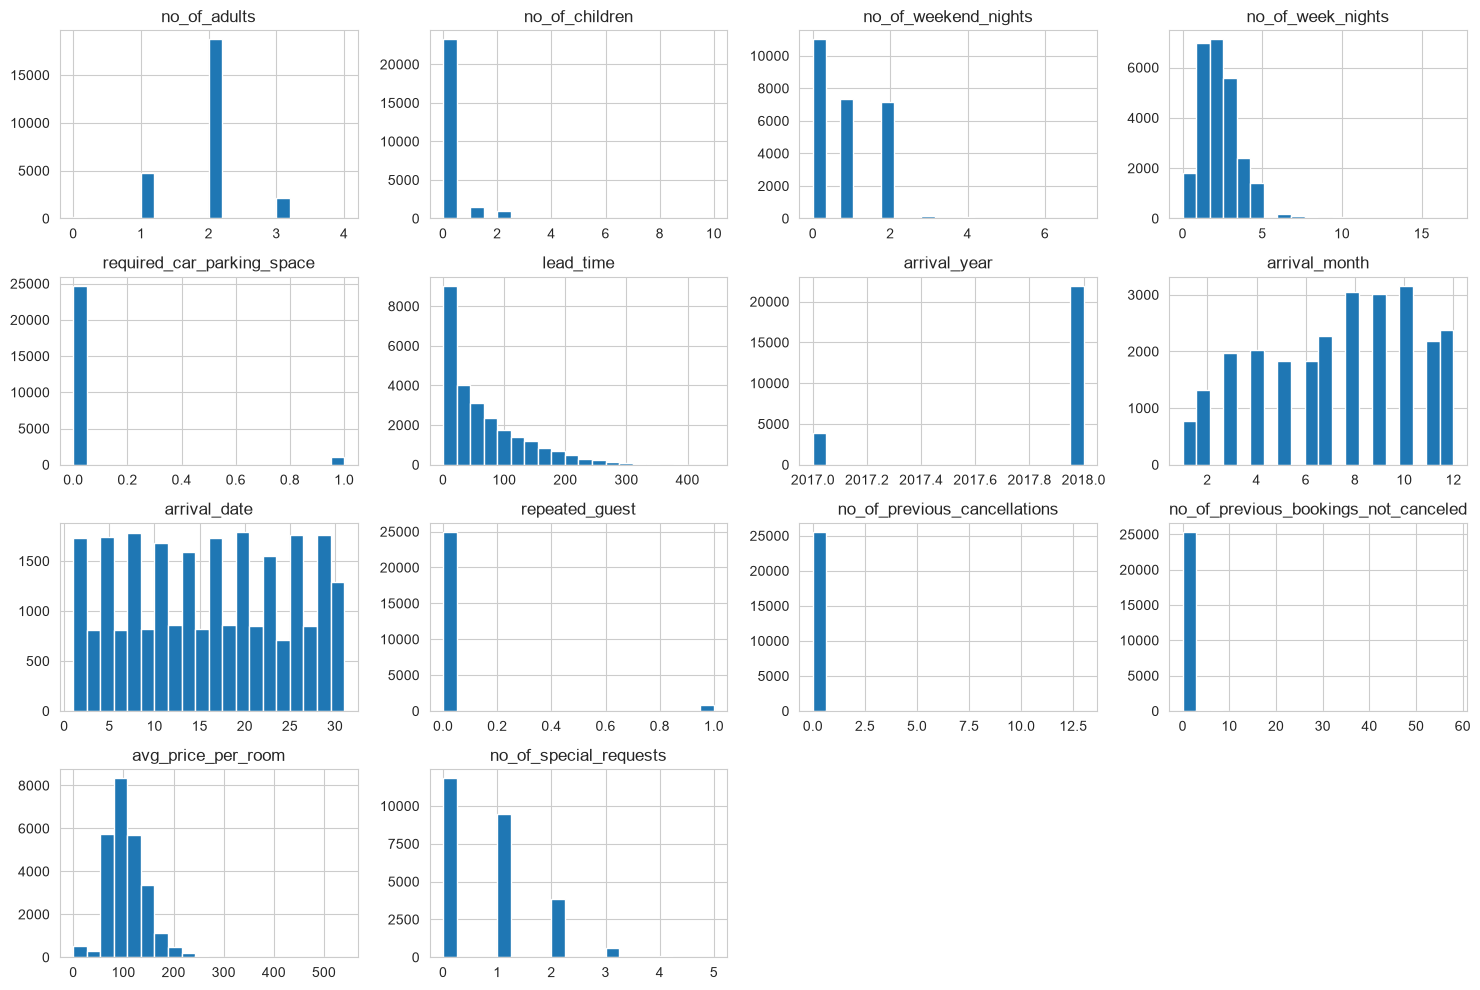

In [15]:
df[num_cols].hist(figsize=(15,10), bins=20)
plt.tight_layout()
plt.show()

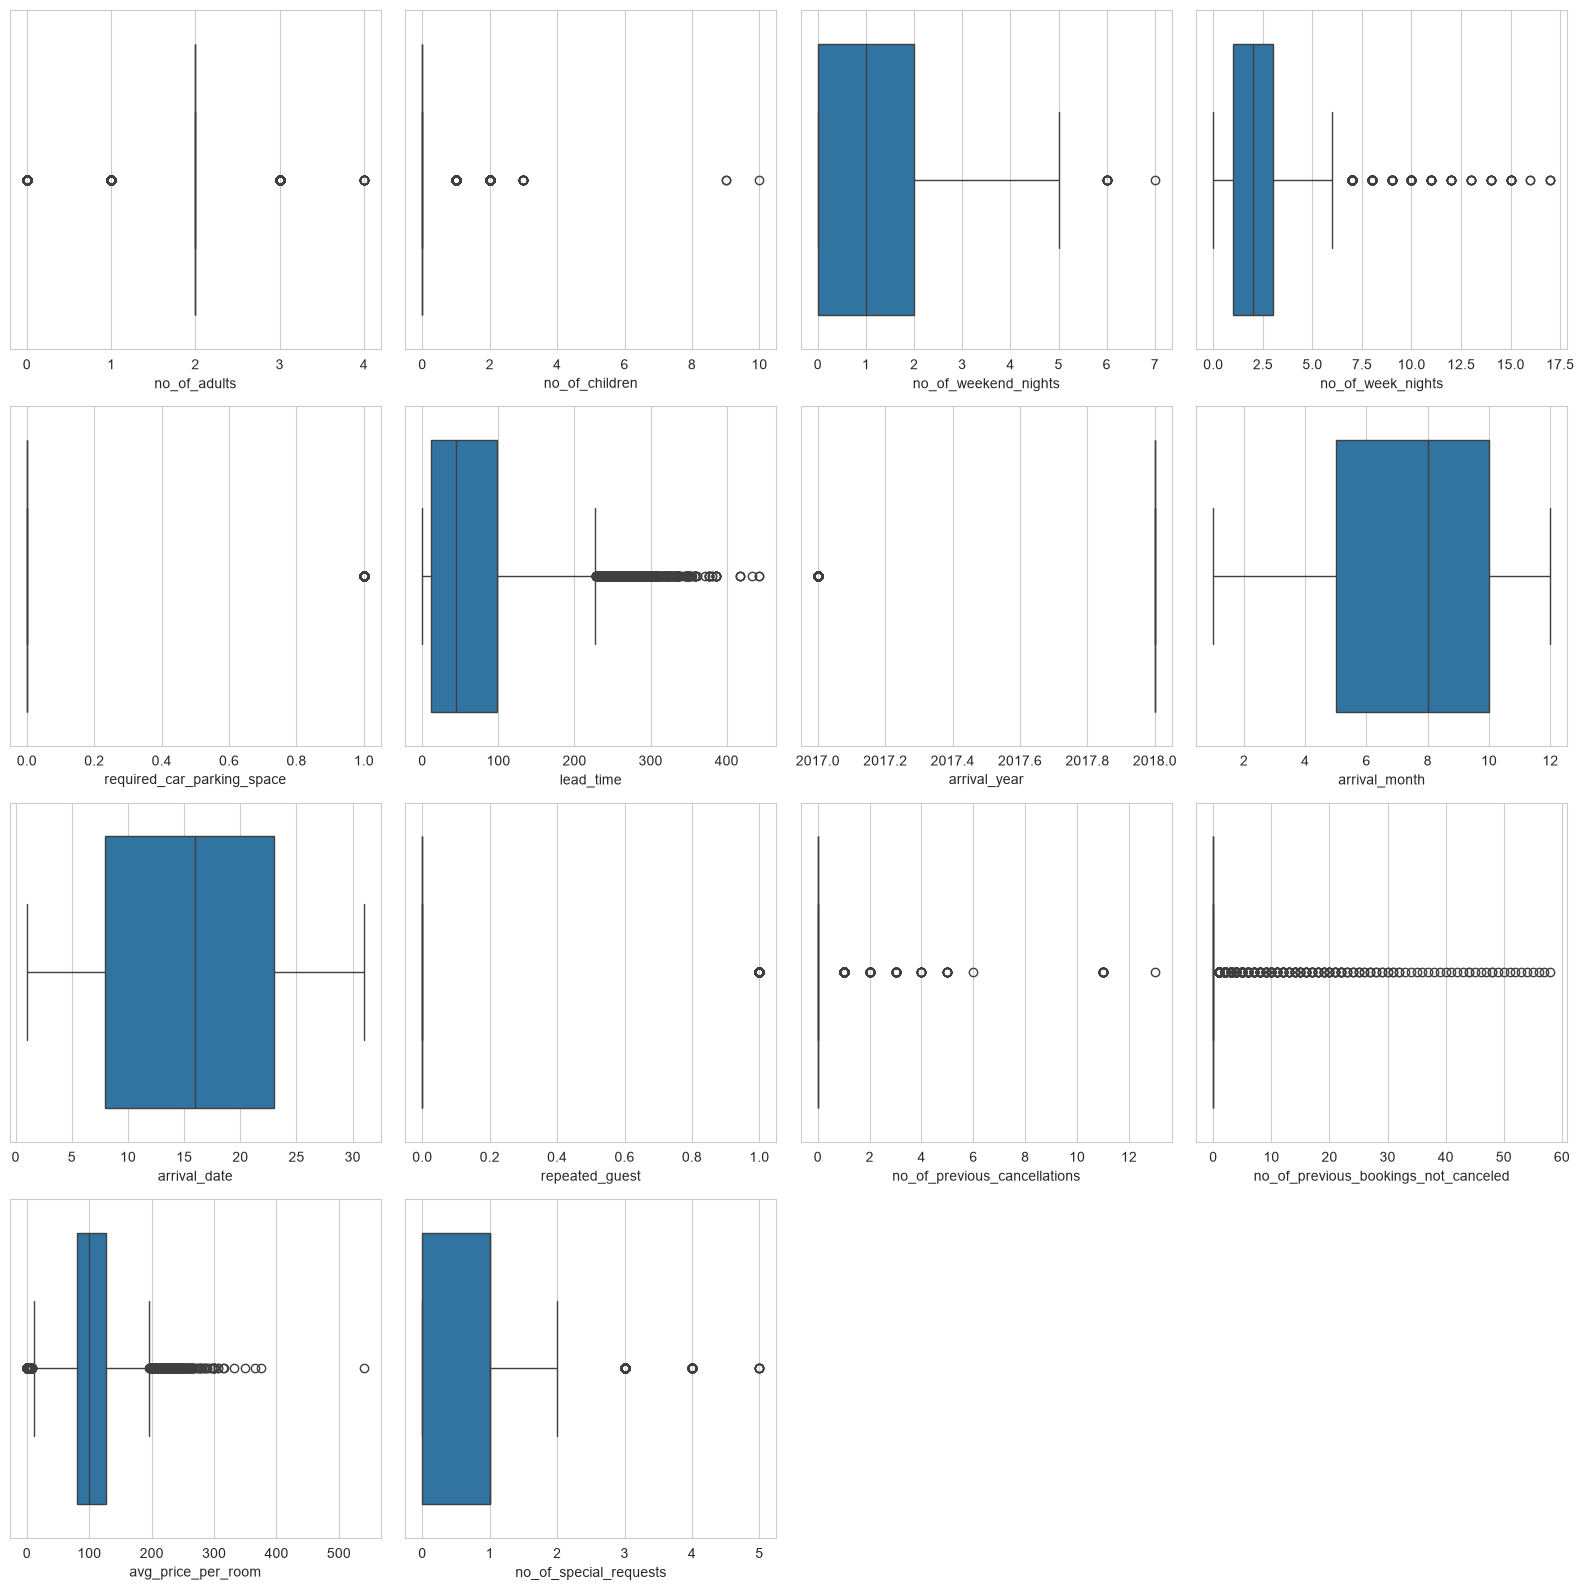

In [16]:
import math

n_cols = 4
n_rows = math.ceil(len(num_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 4))
axes = axes.flatten() 

for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i]

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [17]:
num_cols = df.select_dtypes(include=np.number)

z_scores = np.abs(stats.zscore(num_cols))
threshold = 3
df_clean = df[(z_scores < threshold).all(axis=1)]

In [18]:
df_clean.shape

(22231, 16)

In [19]:
df_clean.describe()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests
count,22231.000000,22231.000000,22231.000000,22231.000000,22231.0,22231.000000,22231.000000,22231.000000,22231.000000,22231.0,22231.0,22231.0,22231.000000,22231.000000
mean,1.921236,0.062750,0.870271,2.213216,0.0,63.837659,2017.848545,7.298952,15.714498,0.0,0.0,0.0,103.848381,0.726103
std,0.502673,0.242519,0.836683,1.308943,0.0,61.000223,0.358500,3.128606,8.876108,0.0,0.0,0.0,32.627161,0.789701
min,1.000000,0.000000,0.000000,0.000000,0.0,0.000000,2017.000000,1.000000,1.000000,0.0,0.0,0.0,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.0,14.000000,2018.000000,5.000000,8.000000,0.0,0.0,0.0,81.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.0,45.000000,2018.000000,8.000000,16.000000,0.0,0.0,0.0,99.450000,1.000000
75%,2.000000,0.000000,2.000000,3.000000,0.0,97.000000,2018.000000,10.000000,23.000000,0.0,0.0,0.0,125.100000,1.000000
max,3.000000,1.000000,3.000000,6.000000,0.0,267.000000,2018.000000,12.000000,31.000000,0.0,0.0,0.0,218.720000,3.000000


In [20]:
 pd.pivot_table(
     df_clean,
     values= 'no_of_adults',
     index= 'arrival_month',
     columns= 'booking_status',
     aggfunc= 'count'
 )

booking_status,Canceled,Not_Canceled
arrival_month,,
1,14,605
2,247,889
3,497,1255
4,558,1243
5,511,1114
6,525,1099
7,757,1162
8,1021,1520
9,738,1882


In [21]:
cancel_rate= df_clean.groupby('arrival_month')['booking_status'].apply(lambda x:(x == 'Canceled').mean())

In [22]:
cancel_rate

arrival_month
1     0.022617
2     0.217430
3     0.283676
4     0.309828
5     0.314462
6     0.323276
7     0.394476
8     0.401810
9     0.281679
10    0.274945
11    0.222854
12    0.125914
Name: booking_status, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

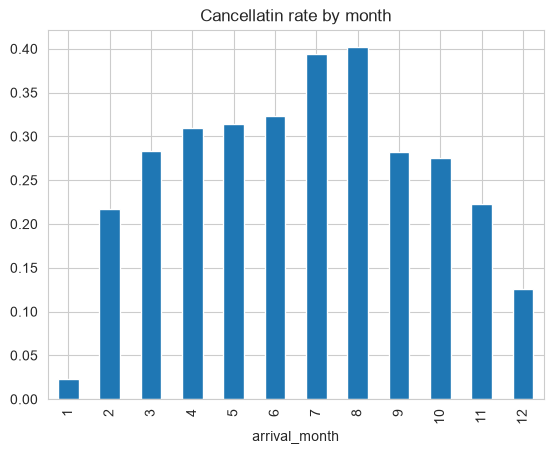

In [23]:
cancel_rate.plot(kind= 'bar', title= 'Cancellatin rate by month')
plt.show

In [24]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 22231 entries, 0 to 25810
Data columns (total 16 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          22231 non-null  int64  
 1   no_of_children                        22231 non-null  int64  
 2   no_of_weekend_nights                  22231 non-null  int64  
 3   no_of_week_nights                     22231 non-null  int64  
 4   type_of_meal_plan                     22231 non-null  str    
 5   required_car_parking_space            22231 non-null  int64  
 6   lead_time                             22231 non-null  int64  
 7   arrival_year                          22231 non-null  int64  
 8   arrival_month                         22231 non-null  int64  
 9   arrival_date                          22231 non-null  int64  
 10  repeated_guest                        22231 non-null  int64  
 11  no_of_previous_cancellations   

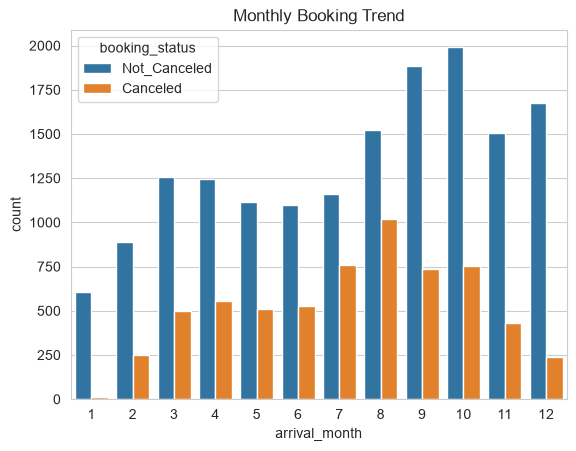

In [25]:
sns.countplot(data= df_clean, x= 'arrival_month', hue= 'booking_status')
plt.title('Monthly Booking Trend')
plt.xticks
plt.show()


In [26]:
encoder = OneHotEncoder(sparse_output=False, drop='first')

encoded_array = encoder.fit_transform(df_clean[['type_of_meal_plan']])

encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['type_of_meal_plan']), index=df_clean.index)

df_clean = df_clean.drop(columns=['type_of_meal_plan']).join(encoded_df)

In [27]:
le = LabelEncoder()

df_clean['booking_status'] = le.fit_transform(df_clean['booking_status'])

In [28]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 22231 entries, 0 to 25810
Data columns (total 18 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   no_of_adults                          22231 non-null  int64  
 1   no_of_children                        22231 non-null  int64  
 2   no_of_weekend_nights                  22231 non-null  int64  
 3   no_of_week_nights                     22231 non-null  int64  
 4   required_car_parking_space            22231 non-null  int64  
 5   lead_time                             22231 non-null  int64  
 6   arrival_year                          22231 non-null  int64  
 7   arrival_month                         22231 non-null  int64  
 8   arrival_date                          22231 non-null  int64  
 9   repeated_guest                        22231 non-null  int64  
 10  no_of_previous_cancellations          22231 non-null  int64  
 11  no_of_previous_bookings_not_can

<Axes: xlabel='booking_status', ylabel='count'>

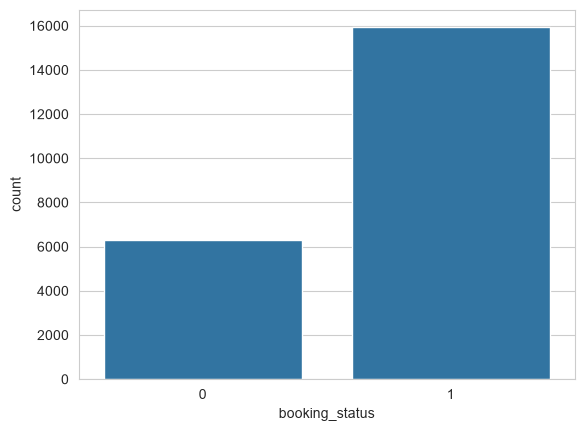

In [29]:
sns.countplot(x= 'booking_status', data= df_clean)

In [30]:
df_clean['booking_status'].value_counts()

booking_status
1    15936
0     6295
Name: count, dtype: int64

In [31]:
X= df_clean.drop('booking_status', axis= 1)

In [32]:
X

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,required_car_parking_space,lead_time,arrival_year,arrival_month,arrival_date,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,type_of_meal_plan_Meal Plan 2,type_of_meal_plan_Meal Plan 3,type_of_meal_plan_Not Selected
0,2,0,1,2,0,224,2017,10,2,0,0,0,65.00,0,0.0,0.0,0.0
1,2,0,2,3,0,5,2018,11,6,0,0,0,106.68,1,0.0,0.0,1.0
2,1,0,2,1,0,1,2018,2,28,0,0,0,60.00,0,0.0,0.0,0.0
3,2,0,0,2,0,211,2018,5,20,0,0,0,100.00,0,0.0,0.0,0.0
4,2,0,1,1,0,48,2018,4,11,0,0,0,94.50,0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25805,2,0,2,2,0,8,2018,3,4,0,0,0,85.96,1,0.0,0.0,0.0
25807,3,0,2,6,0,85,2018,8,3,0,0,0,167.80,1,0.0,0.0,0.0
25808,2,0,1,3,0,228,2018,10,17,0,0,0,90.95,2,0.0,0.0,0.0
25809,2,0,2,6,0,148,2018,7,1,0,0,0,98.39,2,0.0,0.0,0.0


In [33]:
y = df_clean['booking_status']

In [34]:
y

0        1
1        1
2        0
3        0
4        0
        ..
25805    0
25807    1
25808    0
25809    1
25810    0
Name: booking_status, Length: 22231, dtype: int64

In [35]:
X_train, X_test, y_train, y_test = train_test_split (X,y, test_size=0.20, random_state=42)

In [36]:
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)

In [37]:
rf_classifier.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [38]:
y_pred = rf_classifier.predict(X_test)


In [39]:
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8246

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.62      0.67      1301
           1       0.85      0.91      0.88      3146

    accuracy                           0.82      4447
   macro avg       0.80      0.76      0.78      4447
weighted avg       0.82      0.82      0.82      4447

Confusion Matrix:
[[ 801  500]
 [ 280 2866]]


In [40]:
y_prob = rf_classifier.predict_proba(X_test)[:, 1]


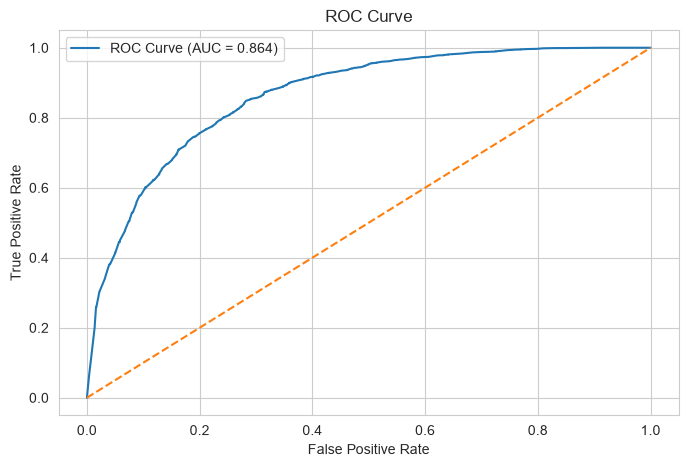

ROC-AUC Score: 0.8639013317058177


In [41]:
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

print("ROC-AUC Score:", auc)

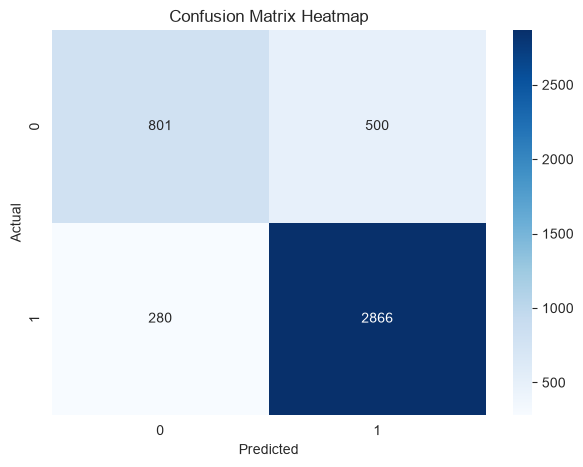

In [42]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')

plt.show()

In [43]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

results = []

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)

In [44]:
comparison_df.sort_values(by='Accuracy',ascending=False)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
2,Random Forest,0.824601,0.851456,0.910998,0.880221,0.863901
3,XGBoost,0.823477,0.856970,0.900826,0.878351,0.880537
1,Decision Tree,0.773780,0.845607,0.832168,0.838834,0.733235
0,Logistic Regression,0.769058,0.798031,0.901780,0.846739,0.798452


In [45]:
final_model = RandomForestClassifier(
    random_state=42
)

final_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [46]:
sample = X_test.iloc[[1]]

prediction = final_model.predict(sample)
probability = final_model.predict_proba(sample)

if prediction[0] == 0:
    print("Booking Status: Not Canceled")
    print("Not Cancellation Probability:", round(probability[0][0] * 100, 2), "%")
else:
    print("Booking Status: Canceled")
    print("Cancellation Probability:", round(probability[0][1] * 100, 2), "%")

Booking Status: Canceled
Cancellation Probability: 95.0 %


In [47]:
for i in range(len(X_test)):
    sample = X_test.iloc[[i]]
    prediction = final_model.predict(sample)

    if prediction[0] == 0:
        print("Booking Status: Not Canceled")
        print("Row Index:", i)
        break

Booking Status: Not Canceled
Row Index: 6
